# Постоянный public train +0/20/60/100% синтетики

В каждом fit сохранены все3398 исходных public train. Синтетический пул:3000 own_v3train +100новых авторских текстов. Добавки:0/620/1860/3100. Подвыборки вложенные, seed42; новые авторские пары сохраняются целиком, темы представлены пропорционально.

Архитектура неизменна: word(1,3),char_wb(3,5),18k+28k,sublinear_tf=True,те же SGD,thresholds0.5. Этот notebook только читает результаты: обучения/подбора параметров нет.

Official public208 — тест организаторов с известными конфликтами/пересечениями. Public729 — **validation**, не финальный test. V3test600 и новые20 сохранялись внеfit. Новые20 —10авторских сюжетов, не репрезентативный независимый человеческий gold.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'avito_compare').is_dir() and (p/'output').is_dir())
OUT=ROOT/'output/v3-fraction-study'
s=json.loads((OUT/'summary.json').read_text());runs=s['runs']
def table(headers,rows):
    text='| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'
    display(Markdown(text+'\n'.join('| '+' | '.join(map(str,r))+' |' for r in rows)))
table(['Добавка, %','Public train','Синтетический train','Official public208 F1','Public validation729 F1','V3test600 F1','Новые20 F1','Fit,s'],[[p,r['public_rows'],r['synthetic_rows'],*[f"{r['evaluation'][k]['micro_f1']:.6f}" for k in ['official_public_test_208','public_validation_729','v3_test_600','new_control_20']],f"{r['fit']['fit_wall_seconds']:.2f}"] for p,r in runs.items()])
assert all(r['public_rows']==3398 and r['fit']['thresholds']==[.5]*5 for r in runs.values())
table(['Добавка,%','Положительных102','103','104','105','106'],[[p,*r['synthetic_positive_counts'].values()] for p,r in runs.items()])

| Добавка, % | Public train | Синтетический train | Official public208 F1 | Public validation729 F1 | V3test600 F1 | Новые20 F1 | Fit,s |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 3398 | 0 | 0.814815 | 0.937124 | 0.183099 | 0.190476 | 6.16 |
| 20 | 3398 | 620 | 0.820588 | 0.935086 | 0.605280 | 0.529412 | 7.65 |
| 60 | 3398 | 1860 | 0.819383 | 0.935150 | 0.662569 | 0.484848 | 8.99 |
| 100 | 3398 | 3100 | 0.822320 | 0.934426 | 0.681818 | 0.457143 | 10.40 |

| Добавка,% | Положительных102 | 103 | 104 | 105 | 106 |
| --- | --- | --- | --- | --- | --- |
| 0 | 0 | 0 | 0 | 0 | 0 |
| 20 | 268 | 269 | 257 | 259 | 262 |
| 60 | 827 | 817 | 815 | 798 | 828 |
| 100 | 1359 | 1366 | 1358 | 1370 | 1375 |

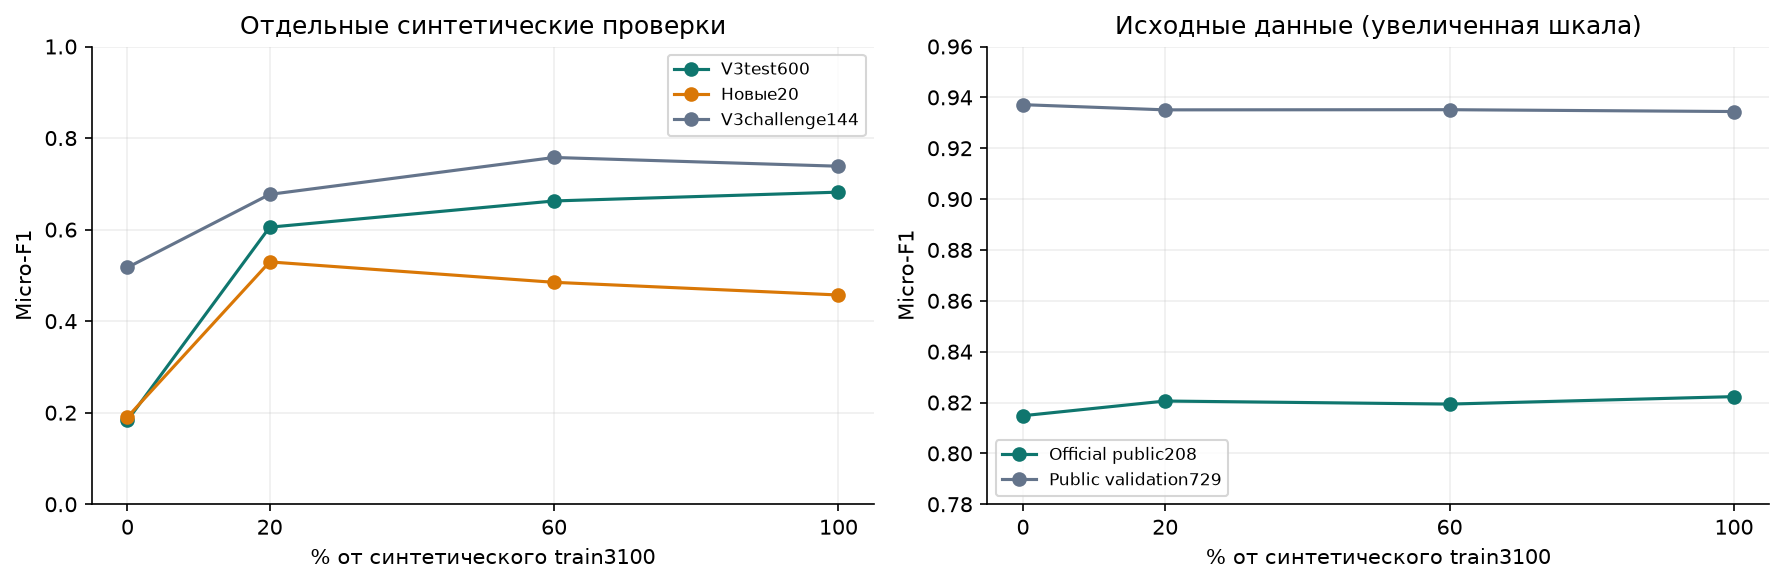

In [2]:
plt.rcParams.update({'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
x=[int(k) for k in runs]
fig,axes=plt.subplots(1,2,figsize=(12,4))
for key,label,color in [('v3_test_600','V3test600','#0f766e'),('new_control_20','Новые20','#d97706'),('v3_challenge_144','V3challenge144','#64748b')]:
    axes[0].plot(x,[r['evaluation'][key]['micro_f1'] for r in runs.values()],marker='o',label=label,color=color)
axes[0].set(title='Отдельные синтетические проверки',ylabel='Micro-F1',ylim=(0,1))
for key,label,color in [('official_public_test_208','Official public208','#0f766e'),('public_validation_729','Public validation729','#64748b')]:
    axes[1].plot(x,[r['evaluation'][key]['micro_f1'] for r in runs.values()],marker='o',label=label,color=color)
axes[1].set(title='Исходные данные (увеличенная шкала)',ylabel='Micro-F1',ylim=(.78,.96))
for ax in axes:ax.set_xticks(x);ax.set_xlabel('% от синтетического train3100');ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'01_fraction_quality.png',dpi=150,bbox_inches='tight');plt.close(fig)
display(Image(filename=str(OUT/'01_fraction_quality.png')))

In [3]:
for name in ['official_public_test_208','official_clean_unique','public_validation_729','v3_test_600','new_control_20','v3_challenge_144']:
    display(Markdown('### '+name))
    table(['Добавка,%','Micro-F1','Macro-F1','P','R','FP','FN','Exact set'],[[p,*[f"{r['evaluation'][name][k]:.5f}" for k in ['micro_f1','macro_f1','micro_precision','micro_recall']],r['evaluation'][name]['fp'],r['evaluation'][name]['fn'],f"{r['evaluation'][name]['exact_set_accuracy']:.5f}"] for p,r in runs.items()])
table(['Добавка,%','Fit,s','PeakRSS,MiB','Модель,MiB','Word/char'],[[p,round(r['fit']['fit_wall_seconds'],3),round(r['fit']['fit_peak_process_rss_mib'],1),round(r['fit']['artifact_bytes']/1024**2,3),f"{r['fit']['dimensions']['word']}/{r['fit']['dimensions']['char']}"] for p,r in runs.items()])

### official_public_test_208

| Добавка,% | Micro-F1 | Macro-F1 | P | R | FP | FN | Exact set |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.81481 | 0.80243 | 0.72368 | 0.93220 | 105 | 20 | 0.67308 |
| 20 | 0.82059 | 0.80901 | 0.72468 | 0.94576 | 106 | 16 | 0.68269 |
| 60 | 0.81938 | 0.80827 | 0.72280 | 0.94576 | 107 | 16 | 0.67308 |
| 100 | 0.82232 | 0.81091 | 0.72539 | 0.94915 | 106 | 15 | 0.68269 |

### official_clean_unique

| Добавка,% | Micro-F1 | Macro-F1 | P | R | FP | FN | Exact set |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.74236 | 0.74020 | 0.66406 | 0.84158 | 43 | 16 | 0.72807 |
| 20 | 0.75862 | 0.75761 | 0.67176 | 0.87129 | 43 | 13 | 0.73684 |
| 60 | 0.76068 | 0.76018 | 0.66917 | 0.88119 | 44 | 12 | 0.72807 |
| 100 | 0.76395 | 0.76341 | 0.67424 | 0.88119 | 43 | 12 | 0.73684 |

### public_validation_729

| Добавка,% | Micro-F1 | Macro-F1 | P | R | FP | FN | Exact set |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.93712 | 0.93720 | 0.93866 | 0.93559 | 112 | 118 | 0.81756 |
| 20 | 0.93509 | 0.93507 | 0.93843 | 0.93177 | 112 | 125 | 0.80933 |
| 60 | 0.93515 | 0.93520 | 0.93362 | 0.93668 | 122 | 116 | 0.80521 |
| 100 | 0.93443 | 0.93449 | 0.93545 | 0.93341 | 118 | 122 | 0.80796 |

... (3 outputs left out)

| Добавка,% | Micro-F1 | Macro-F1 | P | R | FP | FN | Exact set |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.19048 | 0.14667 | 0.40000 | 0.12500 | 3 | 14 | 0.25000 |
| 20 | 0.52941 | 0.46762 | 0.50000 | 0.56250 | 9 | 7 | 0.30000 |
| 60 | 0.48485 | 0.43651 | 0.47059 | 0.50000 | 9 | 8 | 0.35000 |
| 100 | 0.45714 | 0.41111 | 0.42105 | 0.50000 | 11 | 8 | 0.30000 |

### v3_challenge_144

| Добавка,% | Micro-F1 | Macro-F1 | P | R | FP | FN | Exact set |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.51724 | 0.53010 | 0.53571 | 0.50000 | 65 | 75 | 0.29167 |
| 20 | 0.67692 | 0.68576 | 0.62857 | 0.73333 | 65 | 40 | 0.44444 |
| 60 | 0.75758 | 0.76597 | 0.69444 | 0.83333 | 55 | 25 | 0.59028 |
| 100 | 0.73846 | 0.74551 | 0.68571 | 0.80000 | 55 | 30 | 0.55556 |

| Добавка,% | Fit,s | PeakRSS,MiB | Модель,MiB | Word/char |
| --- | --- | --- | --- | --- |
| 0 | 6.163 | 475.4 | 2.754 | 18000/28000 |
| 20 | 7.647 | 531.8 | 2.762 | 18000/28000 |
| 60 | 8.986 | 578.5 | 2.764 | 18000/28000 |
| 100 | 10.401 | 606.4 | 2.768 | 18000/28000 |

## Выводы и ограничения

- При добавлении синтетики v3test существенно улучшился; лучший из предзаданных запусков на нём —100%.
- На полном officialpublic208 F1 вырос0.814815→0.822320. Но там есть ошибки разметки и пересечения с исходным train; показываем также очищенные114.
- На исходной validation есть небольшое снижение0.937124→0.934426. Условие полного отсутствия деградации пока не доказано.
- Новые20 показывают иную динамику: лучшийF1 на20%, и лишь1из10контрастныхпар целиком решена смешанными моделями. Нельзя объявлять все сложные случаи закрытыми.
- Никаких альтернативных порогов или гиперпараметров не подбирали. Вывод о количестве синтетики ограничен одной вложенной случайной серией, не причинным эффектом именно100новых строк.
- Ни production-модель, ни исходныйpublic/v3 не заменялись. Версии, настройки, хэши иIDвыбранных примеров:summary.json. Все показатели:report.md. Подробности новых текстов:datasets/context_pairs_100/README.md.

Каноническийv3 snapshot:dataset_v3@0882f80. Его можно получить отдельным gitworktree; обучение описано в avito_compare/README.md. Веса и подготовленныеJSONLвoutput не коммитятся.